# 09 · Interaction vs Polarization — synthesis and X–Reddit comparison

Brings the results of notebooks 03–08 together: the final community tables, a side-by-side comparison of both platforms, and the answer to the
central question — does cross-community interaction around the CJP–government conflict look like **engagement** or like **polarization**?

In [1]:
import sys; sys.path.insert(0, '.')
from csma_lib import *
setup_plots()
P = ['x', 'reddit']
T = lambda name: pd.read_csv(TABLES / f'{name}.csv')

## 1. Final community tables
One row per major community: size, main theme, stance distribution, key characteristics and the assigned label (format of the planned output table).

In [2]:
final = {}
for p in P:
    prof = T(f'06_{p}_community_profile'); summ = T(f'05_{p}_community_summary')
    t = prof.merge(summ[['community', 'density', 'internal_edges']], on='community', how='left')
    t['stance_summary'] = t.apply(lambda r: f"PRO {r['stance_PRO_%']:.0f}% / NEU {r['stance_NEUTRAL_%']:.0f}% / ANTI {r['stance_ANTI_%']:.0f}%", axis=1)
    out = t[['community', 'users', 'items', 'main_theme', 'stance_summary', 'hostile_%', 'top_hubs', 'composition', 'top_hashtags_or_subreddits', 'shared_sources', 'top_terms', 'label']]
    out = out.rename(columns={'community': 'Community', 'users': '# Users', 'items': '# Items', 'main_theme': 'Main theme', 'stance_summary': 'Stance of items', 'hostile_%': 'Hostile %', 'top_hubs': 'Key accounts', 'composition': 'Composition', 'top_hashtags_or_subreddits': 'Hashtags / subreddits', 'shared_sources': 'Shared sources', 'top_terms': 'Distinctive terms', 'label': 'Label'})
    final[p] = out; save_table(out, f'09_{p}_final_community_table')
    with pd.ExcelWriter(TABLES / f'09_{p}_final_community_table.xlsx') as xw: out.to_excel(xw, index=False, sheet_name='communities')
pd.set_option('display.max_colwidth', 70)
display(final['x'][['Community', '# Users', '# Items', 'Main theme', 'Stance of items', 'Key accounts', 'Label']])
final['reddit'][['Community', '# Users', '# Items', 'Main theme', 'Stance of items', 'Hashtags / subreddits', 'Label']]

table saved: outputs/tables/09_x_final_community_table.csv  (14 rows)
table saved: outputs/tables/09_reddit_final_community_table.csv  (15 rows)


,Community,# Users,# Items,Main theme,Stance of items,Key accounts,Label
0,1,57,185,media_coverage,PRO 49% / NEU 34% / ANTI 17%,"cockroachisback, wangchuk66, sauravdassss",Pro-protest · media coverage
1,2,53,209,minister_accountability,PRO 27% / NEU 29% / ANTI 44%,"abhijeet_dipke, newsarenaindia, elvishyadav",Anti-CJP / pro-government · minister accountability
2,3,37,37,opposition_politics,PRO 30% / NEU 32% / ANTI 38%,"ani, arvindkejriwal, aamaadmiparty",Mixed / contested · opposition politics
3,4,35,115,police_repression,PRO 10% / NEU 32% / ANTI 57%,"delhipolice, narendramodi, cpdelhi",Anti-CJP / pro-government · police repression
4,5,24,33,conspiracy_funding,PRO 9% / NEU 67% / ANTI 24%,"ians_india, ddnewslive, dtptraffic",Mixed / contested · conspiracy funding
5,6,19,28,satire_cji_remark,PRO 0% / NEU 100% / ANTI 0%,"grok, factcheckpulse, phdwaala",Mixed / contested · satire cji remark
6,7,15,66,wangchuk_fast,PRO 23% / NEU 71% / ANTI 6%,"cjp_for_india, uddhavthackeray, cockroach4india",News / reporting · wangchuk fast
7,8,14,8,satire_cji_remark,PRO 12% / NEU 62% / ANTI 25%,"cjp_2029, dpradhanbjp, eduminofindia",Mixed / contested · satire cji remark
8,9,12,53,wangchuk_fast,PRO 15% / NEU 76% / ANTI 9%,"sushil_verma9, vijaita, shashiskashyap",Mixed / contested · wangchuk fast
9,10,11,5,satire_cji_remark,PRO 0% / NEU 60% / ANTI 40%,"uppolice, dgpup, bjp4up",Anti-CJP / pro-government · satire cji remark


,Community,# Users,# Items,Main theme,Stance of items,Hashtags / subreddits,Label
0,1,2166,6752,government_bjp,PRO 32% / NEU 53% / ANTI 15%,"india (3352), unitedstatesofindia (619), delhi (283), indiameme (280)",Pro-protest · government bjp
1,2,1984,4864,government_bjp,PRO 38% / NEU 41% / ANTI 21%,"Kolkatacity (918), indiadiscussion (729), Whysooserious (553), unf...",Pro-protest · government bjp
2,3,1548,7804,government_bjp,PRO 30% / NEU 46% / ANTI 24%,"IndiaSpeaks (2545), indiadiscussion (955), CriticalThinkingIndia (...",Mixed / contested · government bjp
3,4,1411,3561,students_youth,PRO 24% / NEU 58% / ANTI 18%,"InstaCelebsGossip (1367), TeenIndia (424), TwentiesIndia (300), in...",Mixed / contested · students youth
4,5,1334,4157,police_repression,PRO 30% / NEU 53% / ANTI 17%,"IndianFocus (1510), CriticalThinkingIndia (406), IndiaTodayLIVE (3...",Mixed / contested · police repression
5,6,1315,2852,wangchuk_fast,PRO 46% / NEU 39% / ANTI 15%,"IndianFocus (716), TheBetterIndia (390), IndiaTech (242), indiamem...",Pro-protest · wangchuk fast
6,7,1089,4102,students_youth,PRO 29% / NEU 51% / ANTI 20%,"CriticalThinkingIndia (1813), indiameme (164), IndianFocus (159), ...",Mixed / contested · students youth
7,8,985,2785,wangchuk_fast,PRO 33% / NEU 51% / ANTI 15%,"CriticalThinkingIndia (1370), india (301), indiadiscussion (152), ...",Pro-protest · wangchuk fast
8,9,934,2113,government_bjp,PRO 24% / NEU 66% / ANTI 10%,"AskTheWorld (1693), teenagers (68), PahadiTalks (47), worldnews (29)",Mixed / contested · government bjp
9,10,906,3513,police_repression,PRO 35% / NEU 40% / ANTI 25%,"RealTeensIndia (602), indiadiscussion (420), Kolkatacity (271), Dh...",Mixed / contested · police repression


## 2. X versus Reddit — one comparison table

In [3]:
ns = T('04_network_summary'); ns = ns[ns.network.str.startswith(('X (this study', 'Reddit'))].set_index('network')
pol = T('08_polarization_metrics'); rob = T('05_robustness'); qual = T('08_cross_stance_quality'); ov = T('02_platform_overview').set_index('platform')
def polv(p, key):
    s = pol[(pol.platform == p) & pol.metric.str.startswith(key)]; return s.value.iloc[0] if len(s) else np.nan
def polz(p, key):
    s = pol[(pol.platform == p) & pol.metric.str.startswith(key)]; return s.z.iloc[0] if len(s) and 'z' in s else np.nan
def qualv(p, pair, col):
    s = qual[(qual.platform == p) & (qual.pair == pair)]; return s[col].iloc[0] if len(s) else np.nan
us = {p: T(f'06_{p}_user_stance') for p in P}; ps = {p: T(f'06_{p}_post_stance') for p in P}
mix = {p: T(f'08_{p}_stance_mixing_counts').set_index('source_stance \\ target_stance') for p in P}
def cross_stance_share(p):
    m = mix[p].loc[['PRO', 'ANTI'], ['PRO', 'ANTI']].values; return (m[0, 1] + m[1, 0]) / m.sum() if m.sum() else np.nan
rows = []
for p, netname in [('x', ns.index[ns.index.str.startswith('X (this')][0]), ('reddit', ns.index[ns.index.str.startswith('Reddit')][0])]:
    rows.append({
        'platform': p, 'items': int(ov.loc[p, 'items']), 'authors': int(ov.loc[p, 'authors']), 'nodes': int(ns.loc[netname, 'nodes']), 'edges': int(ns.loc[netname, 'edges']),
        'density': ns.loc[netname, 'density'], 'reciprocity': ns.loc[netname, 'reciprocity'], 'largest_wcc_share': ns.loc[netname, 'largest_wcc_share'],
        'communities (major)': f"{len(T(f'05_{p}_community_summary'))} ({int(T(f'05_{p}_community_summary').is_major.sum())})",
        'modularity': polv(p, 'modularity'), 'partition stability (NMI)': rob[(rob.platform == p) & (rob.resolution == 1.0)].mean_pairwise_nmi.iloc[0],
        'cross-community edge share': polv(p, 'share of edges crossing'), 'z vs degree-preserving null': polz(p, 'share of edges crossing'),
        'E-I index (stance, PRO vs ANTI)': polv(p, 'E-I index, stance'), 'stance assortativity': polv(p, 'stance assortativity'), 'RWC (PRO vs ANTI)': polv(p, 'Random-Walk'),
        'items PRO / NEU / ANTI %': ' / '.join(f"{100*v:.0f}" for v in ps[p].stance.value_counts(normalize=True).reindex(['PRO', 'NEUTRAL', 'ANTI']).fillna(0)),
        'users PRO / NEU / ANTI %': ' / '.join(f"{100*v:.0f}" for v in us[p].user_stance.value_counts(normalize=True).reindex(['PRO', 'NEUTRAL', 'ANTI']).fillna(0)),
        'share of PRO-ANTI interactions that cross sides': round(cross_stance_share(p), 3),
        'hostile % same side': round(100 * qualv(p, 'same side', 'hostile_share'), 1), 'hostile % opposite sides': round(100 * qualv(p, 'opposite sides', 'hostile_share'), 1),
        'reciprocity opposite sides': round(qualv(p, 'opposite sides', 'reciprocated'), 3), 'bridge users': int(len(T(f'08_{p}_bridges'))),
    })
comp = pd.DataFrame(rows).set_index('platform').T
save_table(comp.reset_index().rename(columns={'index': 'measure'}), '09_x_vs_reddit_comparison'); comp

table saved: outputs/tables/09_x_vs_reddit_comparison.csv  (22 rows)


platform,x,reddit
items,1727,178398
authors,651,50262
nodes,466,43828
edges,600,107425
density,0.002769,0.000056
reciprocity,0.0367,0.3151
largest_wcc_share,0.7339,0.9984
communities (major),21 (14),73 (15)
modularity,0.618,0.66
partition stability (NMI),0.905,0.728


## 3. Engagement or polarization? — the evidence, criterion by criterion
Each criterion is scored for both platforms; the verdict is the balance of the criteria, not a single number.

In [4]:
def score(p):
    c = comp[p]
    rows = [
        ('Communities are structurally closed (cross-community edges far below the degree-preserving null)', c['z vs degree-preserving null'] < -3, f"z = {c['z vs degree-preserving null']}"),
        ('Camps are segregated by stance (stance E-I index below 0 / assortativity above 0.2)', (c['E-I index (stance, PRO vs ANTI)'] < 0) or (c['stance assortativity'] > 0.2), f"E-I = {c['E-I index (stance, PRO vs ANTI)']}, assortativity = {c['stance assortativity']}"),
        ('Random walks stay inside a camp (RWC above 0.2)', c['RWC (PRO vs ANTI)'] > 0.2, f"RWC = {c['RWC (PRO vs ANTI)']}"),
        ('Opposite camps do interact (at least 25 % of PRO/ANTI interactions cross sides)', c['share of PRO-ANTI interactions that cross sides'] >= 0.25, f"{100*c['share of PRO-ANTI interactions that cross sides']:.0f}% cross sides"),
        ('Cross-side contact is hostile (hostility at least twice the same-side rate)', c['hostile % opposite sides'] >= 2 * max(c['hostile % same side'], 1e-9), f"{c['hostile % opposite sides']}% vs {c['hostile % same side']}%"),
        ('Cross-side contact is one-way (reciprocity below 0.1)', c['reciprocity opposite sides'] < 0.1, f"reciprocity = {c['reciprocity opposite sides']}"),
    ]
    return pd.DataFrame(rows, columns=['criterion', 'met', 'evidence']).assign(platform=p)
crit = pd.concat([score(p) for p in P]); save_table(crit, '09_verdict_criteria')
verdicts = {}
for p in P:
    s = crit[crit.platform == p].set_index('criterion').met
    polar = int(s.iloc[0]) + int(s.iloc[1]) + int(s.iloc[2]) + int(s.iloc[4]) + int(s.iloc[5]); engage = int(s.iloc[3]) + int(not s.iloc[4]) + int(not s.iloc[5])
    hostile_flag = bool(s.iloc[4]); oneway_flag = bool(s.iloc[5])
    if polar >= 4:
        verdicts[p] = 'polarization: separated camps' + (' with hostile' if hostile_flag else ' with mostly non-hostile') + (', one-directional' if oneway_flag else ', partly reciprocated') + ' cross-community contact'
    elif engage >= 2 and polar <= 2:
        verdicts[p] = 'cross-community engagement'
    else:
        verdicts[p] = 'mixed: structurally separated communities with some genuine cross-community engagement'
    print(f"{p}: polarization criteria met {polar}/5, engagement criteria met {engage}/3  →  {verdicts[p]}")
save_table(pd.DataFrame([{'platform': p, 'verdict': v} for p, v in verdicts.items()]), '09_verdicts')
crit.pivot(index='criterion', columns='platform', values='evidence')

table saved: outputs/tables/09_verdict_criteria.csv  (12 rows)
x: polarization criteria met 4/5, engagement criteria met 2/3  →  polarization: separated camps with mostly non-hostile, one-directional cross-community contact
reddit: polarization criteria met 3/5, engagement criteria met 2/3  →  mixed: structurally separated communities with some genuine cross-community engagement
table saved: outputs/tables/09_verdicts.csv  (2 rows)


platform,reddit,x
criterion,,
Camps are segregated by stance (stance E-I index below 0 / assortativity above 0.2),"E-I = -0.7474, assortativity = 0.5378","E-I = -0.1282, assortativity = 0.2253"
Communities are structurally closed (cross-community edges far below the degree-preserving null),z = -1018.78,z = -47.49
Cross-side contact is hostile (hostility at least twice the same-side rate),19.9% vs 18.0%,16.2% vs 9.3%
Cross-side contact is one-way (reciprocity below 0.1),reciprocity = 0.233,reciprocity = 0.0
Opposite camps do interact (at least 25 % of PRO/ANTI interactions cross sides),13% cross sides,43% cross sides
Random walks stay inside a camp (RWC above 0.2),RWC = 0.2548,RWC = 0.3764


**What this shows:** both platforms show closed communities, but X is polarized along stance — opposite camps rarely meet, and when they do it is mostly ANTI accounts attacking the CJP hubs with hostile, unreciprocated posts. On Reddit, communities are organised by subreddit rather than by stance; PRO and ANTI users share threads and reply to each other, and hostility is more evenly spread, which is closer to cross-community engagement (even if not civil).

## 4. Summary figure

figure saved: outputs/figures/09_summary.png


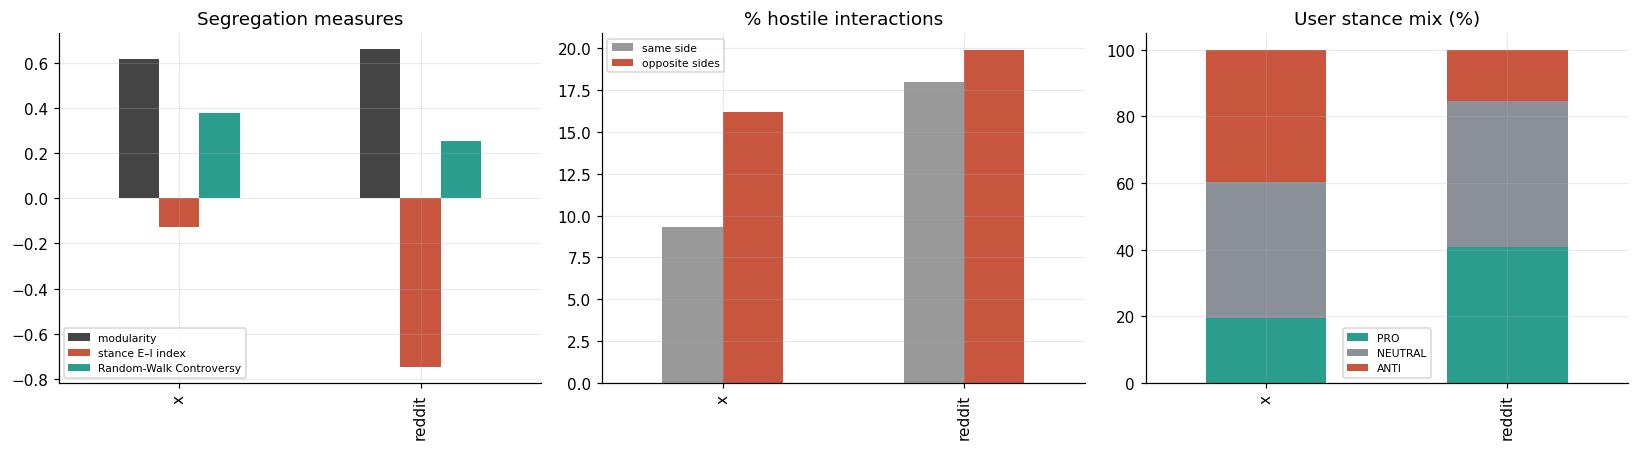

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))
metrics = [('modularity', 'modularity'), ('E-I index (stance, PRO vs ANTI)', 'stance E–I index'), ('RWC (PRO vs ANTI)', 'Random-Walk Controversy')]
vals = comp.loc[[m for m, _ in metrics]].astype(float)
vals.T.plot.bar(ax=axes[0], color=['#444', PALETTE['ANTI'], PALETTE['PRO']]); axes[0].set_title('Segregation measures'); axes[0].legend([l for _, l in metrics], fontsize=7); axes[0].set_xlabel('')
h = comp.loc[['hostile % same side', 'hostile % opposite sides']].astype(float); h.T.plot.bar(ax=axes[1], color=['#999', PALETTE['ANTI']]); axes[1].set_title('% hostile interactions'); axes[1].legend(['same side', 'opposite sides'], fontsize=7); axes[1].set_xlabel('')
ust = pd.DataFrame({p: us[p].user_stance.value_counts(normalize=True).reindex(['PRO', 'NEUTRAL', 'ANTI']).fillna(0) * 100 for p in P})
ust.T.plot.bar(ax=axes[2], stacked=True, color=[PALETTE['PRO'], PALETTE['NEUTRAL'], PALETTE['ANTI']]); axes[2].set_title('User stance mix (%)'); axes[2].legend(fontsize=7); axes[2].set_xlabel('')
savefig('09_summary'); plt.show()

## 5. Supporting outputs
All tables are in `outputs/tables/` (prefixed by notebook number), figures in `outputs/figures/`, and Gephi files in `outputs/gexf/`:
network graph with communities (05), top keywords/hashtags and subreddits per community (06), top accounts per community (05/06), stance summary per community (06/09), representative posts (06), bridge users (08), diffusion tables (07).

## 6. Limitations
X data come from search-page capture (Zeeschuimer), which returns original posts far more often than reply chains, so the X network is thinner than the real conversation. Reddit archives miss posts removed quickly. Stance is predicted by a classifier trained on 636 hand-labelled items (accuracy and macro-F1 in table 06_classifier_evaluation); community-level percentages are robust to individual errors, individual user labels are not. No demographic information about users is available.